In [35]:
import numpy as np
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt

### Cargar Datos

In [12]:
FILENAME = "dataset_consolidado.csv"

datapath = os.path.join("..","..","data","clean",FILENAME)
df = pd.read_csv(datapath)

In [ ]:
display(df)

,DIA,KW Mycom 1,KW Mycom 2,KW Mycom 3,KW Mycom 4,KW Mycom 5,KW Mycom 6,KW Mycom 7,EE Frio / Hl,KW Bba Glicol Sala MAq,...,Totalizador_Tq_Pulmon,Tot Fermantacion_Cocina,Tot Reposo Inferior,Tot Reposo Superior,Tot Trasiego,Tot A10/20,Tot A40/240/50/60/Centec/Filtro,Tot A130/330/430,"Tot L3, L4 y Planta de CO2",target_Frio_kW_next
0,2020-07-01,0,3600.0,0.0,0,0.0,1013.0,4342.0,333.139535,467.0,...,1775.0,570.17,6323.06,0.1,NaN,NaN,NaN,NaN,NaN,23954.0
1,2020-07-02,701,5848.0,1362.0,2238,0.0,1062.0,5641.0,3.419545,777.0,...,14295.0,694.08,5349.47,0.8,NaN,NaN,NaN,NaN,NaN,28268.0
2,2020-07-03,328,5980.0,5356.0,3321,0.0,1043.0,4792.0,3.787626,824.0,...,8366.0,400.66,4965.47,0.5,NaN,NaN,NaN,NaN,NaN,24246.0
3,2020-07-04,0,6040.0,1407.0,5029,0.0,325.0,4901.0,1.870213,765.0,...,5081.0,447.89,5040.93,1.0,NaN,NaN,NaN,NaN,NaN,29885.0
4,2020-07-05,0,6381.0,2043.0,5501,0.0,2568.0,6222.0,3.354482,786.0,...,12559.0,400.06,5690.25,0.2,NaN,NaN,NaN,NaN,NaN,24449.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1159,2023-10-20,3549,0.0,0.0,576,1279.0,0.0,960.0,NaN,1198.0,...,2369.0,NaN,NaN,NaN,1458.1875,330.125,1636.750,6879.625,76.40625,9481.0
1160,2023-10-21,129,0.0,1736.0,0,1954.0,0.0,196.0,NaN,1041.0,...,1649.0,NaN,NaN,NaN,0.0000,232.375,2194.000,6922.250,40.12500,11587.0
1161,2023-10-22,0,0.0,0.0,0,4094.0,0.0,1814.0,2.782861,1344.0,...,2863.0,NaN,NaN,NaN,0.0000,254.875,2070.875,6019.625,72.56250,10123.0
1162,2023-10-23,0,0.0,0.0,0,4605.0,0.0,0.0,20.765128,1093.0,...,3244.0,NaN,NaN,NaN,0.0000,790.625,1828.250,6030.000,74.53125,10360.0


## EDA Univariado

In [ ]:
print("Porcentaje de valores nulos por columna: (el resto no tiene valores nulos)")
print(df[df.columns[df.isna().any()]].isna().sum().sort_values(ascending=False)/df.shape[0]*100)

Porcentaje de valores nulos por columna:
Tot L3, L4 y Planta de CO2         60.309278
Tot A10/20                         51.460481
Tot  A130/330/430                  51.460481
Tot A40/240/50/60/Centec/Filtro    51.460481
Tot Reposo Inferior                48.453608
Tot Fermantacion_Cocina            48.453608
Tot  Reposo Superior               48.453608
Tot  Trasiego                       5.927835
EE Frio / Hl                        1.804124
dtype: float64


Número de valores cero por columna:


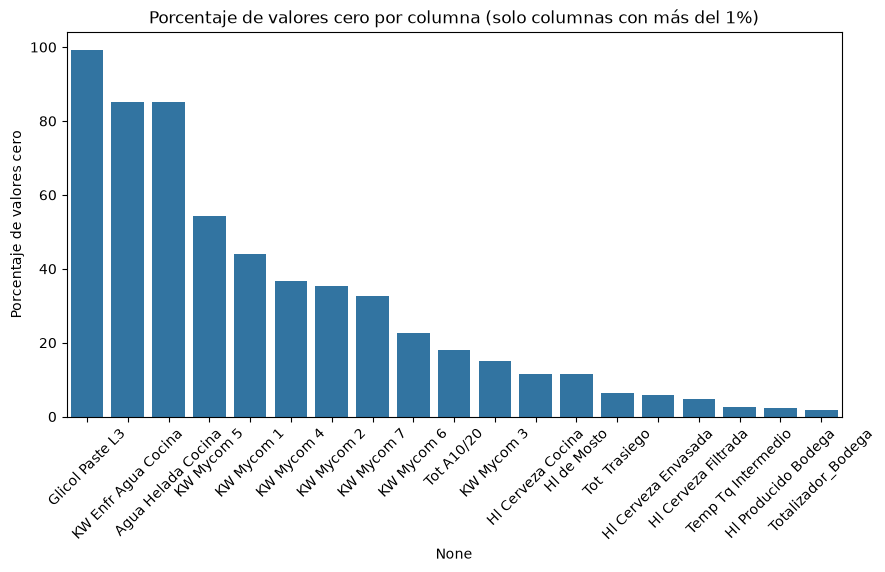

In [77]:
print("Número de valores cero por columna:")
cant_ceros = (df==0).sum().sort_values(ascending=False)/df.shape[0]*100
plt.figure(figsize=(10,5))
sns.barplot(x=cant_ceros.index[cant_ceros>1],y=cant_ceros.values[cant_ceros>1])
plt.xticks(rotation=45)
plt.title("Porcentaje de valores cero por columna (solo columnas con más del 1%)")
plt.ylabel("Porcentaje de valores cero")
plt.show()

In [21]:
display(df.describe(include='all'))    

,DIA,KW Mycom 1,KW Mycom 2,KW Mycom 3,KW Mycom 4,KW Mycom 5,KW Mycom 6,KW Mycom 7,EE Frio / Hl,KW Bba Glicol Sala MAq,...,Totalizador_Tq_Pulmon,Tot Fermantacion_Cocina,Tot Reposo Inferior,Tot Reposo Superior,Tot Trasiego,Tot A10/20,Tot A40/240/50/60/Centec/Filtro,Tot A130/330/430,"Tot L3, L4 y Planta de CO2",target_Frio_kW_next
count,1164,1.164000e+03,1164.000000,1164.000000,1.164000e+03,1164.000000,1164.000000,1.164000e+03,1143.000000,1164.000000,...,1164.000000,600.000000,600.000000,600.000000,1095.000000,565.000000,565.000000,565.000000,462.000000,1.164000e+03
unique,1164,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2020-07-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,1.262211e+04,3706.230241,2634.620275,6.626418e+03,1592.542955,1768.387457,1.097770e+04,6.496176,1288.036942,...,11729.597938,1582.390950,5322.758900,1755.913700,1526.632916,3011.028566,2104.995770,5787.851142,3580.276404,4.624332e+04
std,NaN,2.419960e+05,2860.211749,2118.460459,1.188605e+05,2134.539166,1524.689559,2.590220e+05,50.148025,482.351432,...,4611.811994,8086.149372,2452.718515,13644.782074,8954.535416,2680.144009,1110.392308,1369.046246,4933.896257,3.738803e+05
min,NaN,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,518.630000,2275.780000,3.750000,2.310000e+03
25%,NaN,0.000000e+00,0.000000,487.000000,0.000000e+00,0.000000,91.750000,0.000000e+00,2.192287,877.750000,...,8821.750000,608.557500,3867.045000,2.200000,636.745000,0.000000,1228.130000,4804.010000,474.420000,1.795175e+04
50%,NaN,2.440000e+02,5499.500000,2494.000000,7.755000e+02,0.000000,1632.000000,4.545500e+03,2.666412,1205.000000,...,12656.000000,946.575000,5569.315000,12.305000,1205.280000,4357.710000,1861.310000,5565.940000,1161.615000,2.375450e+04
75%,NaN,5.689500e+03,6111.500000,4445.000000,3.073250e+03,3464.750000,3022.250000,5.805250e+03,3.397267,1736.000000,...,15164.500000,1417.615000,6951.345000,2449.642500,1748.630000,5347.780000,2740.970000,6392.500000,4991.362500,2.932475e+04


Porcentaje de valores cero en Kw Mycom Mean: 0.34%


,DIA,KW Mycom 1,KW Mycom 2,KW Mycom 3,KW Mycom 4,KW Mycom 5,KW Mycom 6,KW Mycom 7,EE Frio / Hl,KW Bba Glicol Sala MAq,...,Tot Fermantacion_Cocina,Tot Reposo Inferior,Tot Reposo Superior,Tot Trasiego,Tot A10/20,Tot A40/240/50/60/Centec/Filtro,Tot A130/330/430,"Tot L3, L4 y Planta de CO2",target_Frio_kW_next,Kw Mycom Mean
293,2021-04-30,5540000,6641.0,3380.0,3151,0.0,4343.0,6728.0,712.156289,1109.0,...,1071.75,9580.25,1.73,2062.52,NaN,NaN,NaN,NaN,29361.0,7.948919e+05
378,2021-07-28,5681,4916.0,5060.0,2870006,4397.0,1030.0,1715.0,3.953632,854.0,...,1212.66,5104.97,177.37,1134.03,NaN,NaN,NaN,NaN,30962.0,4.132579e+05
406,2021-08-25,1350,6654.0,6528.0,2870000,4621.0,2696.0,6725.0,251.376396,927.0,...,926.96,7091.53,6.80,1053.91,NaN,NaN,NaN,NaN,36002.0,4.140820e+05
495,2021-11-28,6130209,6011.0,3573.0,0,5460.0,3009.0,1582.0,735.342168,1138.0,...,793.69,9968.75,0.75,1457.67,NaN,NaN,NaN,NaN,17838.0,8.785491e+05
575,2022-02-18,0,5648.0,5412.0,0,1971.0,3276.0,8840000.0,952.992406,1036.0,...,1259.44,1927.97,5064.13,1673.20,NaN,NaN,NaN,NaN,16649.0,1.265187e+06


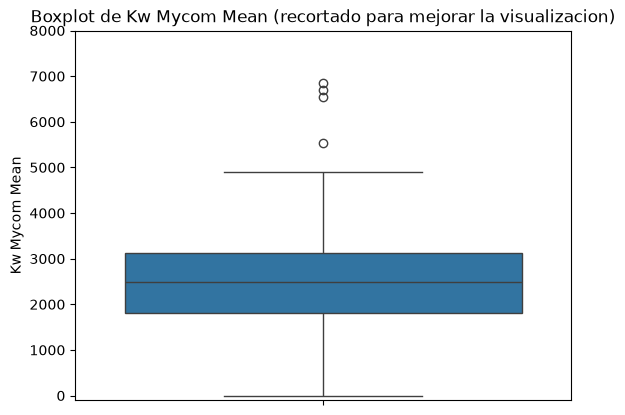

In [ ]:
#Muchos de los valores de Mycom son 0, por lo que se calcula la media de las columnas de Mycom.
#La presencia de outliers imposibilita la correcta visualización del boxplot
df["Kw Mycom Mean"] = df.loc[:, df.columns.str.contains("Mycom")].mean(axis=1)
sns.boxplot(df, y="Kw Mycom Mean")
plt.ylim(-100,8000)
plt.title("Boxplot de Kw Mycom Mean (recortado para mejorar la visualizacion)")
cant_ceros = (df["Kw Mycom Mean"]==0).sum()/df.shape[0]*100
print(f"Porcentaje de valores cero en Kw Mycom Mean: {cant_ceros:.2f}%")
print("Las filas donde se producen outliers extremos:")
display(df[df["Kw Mycom Mean"] > 0.3e6])